# 02 - Distances et partitionnement

Objectif : mesurer la ressemblance entre clients (chapitre 2), puis faire des groupes avec K-means, K-medoids, K-prototypes et GMM (chapitre 3.1).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gower
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances, silhouette_score
from kmodes.kprototypes import KPrototypes

import sys
sys.path.insert(0, "..")
import fonctions

X, y, Xa, Xb = fonctions.preparer()
numeriques, categorielles = fonctions.types_de_variables(X)

# matrice de distances de Gower entre les 4 000 clients
G = gower.gower_matrix(Xb)
print(G.shape)

(4000, 4000)


## 1. Distances du cours

Euclidienne : $d(x,y) = \sqrt{\sum_i (x_i - y_i)^2}$

Manhattan : $d(x,y) = \sum_i |x_i - y_i|$

Gower : $d(i,j) = \dfrac{1}{p}\sum_{k=1}^{p} d_k$ avec $d_k = \dfrac{|x_{ik} - x_{jk}|}{\max_k - \min_k}$ pour une variable numérique, et $d_k = 0$ si égal, $1$ sinon pour une variable catégorielle.

In [2]:
# distances entre les 3 premiers clients
print(X.head(3))
print("Euclidienne :")
print(pairwise_distances(Xa[:3], metric="euclidean").round(2))
print("Manhattan :")
print(pairwise_distances(Xa[:3], metric="manhattan").round(2))
print("Gower :")
print(G[:3, :3].round(3))

   age          job   marital    education default housing loan    contact  \
0   54   technician  divorced     basic.9y      no     yes   no  telephone   
1   46  blue-collar   married     basic.4y      no     yes   no   cellular   
2   26     services   married  high.school      no     yes   no   cellular   

   campaign  previous     poutcome  cons.price.idx  cons.conf.idx  euribor3m  
0         2         0  nonexistent          94.465          -41.8      4.947  
1         1         0  nonexistent          92.893          -46.2      1.299  
2        12         0  nonexistent          93.918          -42.7      4.962  
Euclidienne :
[[0.   4.64 6.05]
 [4.64 0.   6.38]
 [6.05 6.38 0.  ]]
Manhattan :
[[ 0.   14.99 16.34]
 [14.99  0.   15.53]
 [16.34 15.53  0.  ]]
Gower :
[[0.    0.415 0.384]
 [0.415 0.    0.321]
 [0.384 0.321 0.   ]]


### Calcul à la main de Gower (clients 0 et 1)

In [3]:
client0 = X.iloc[0]
client1 = X.iloc[1]
somme = 0

for v in numeriques:
    d = abs(client0[v] - client1[v]) / (X[v].max() - X[v].min())   # écart / étendue
    print(v, ":", round(d, 3))
    somme = somme + d

for v in categorielles:
    if client0[v] == client1[v]:
        d = 0
    else:
        d = 1
    print(v, ":", d)
    somme = somme + d

print("Gower à la main :", round(somme / 14, 4))
print("Gower bibliothèque :", round(G[0, 1], 4))

age : 0.1
campaign : 0.077
previous : 0.0
cons.price.idx : 0.613
cons.conf.idx : 0.184
euribor3m : 0.842
job : 1
marital : 1
education : 1
default : 0
housing : 0
loan : 0
contact : 1
poutcome : 0
Gower à la main : 0.4154
Gower bibliothèque : 0.4154


### Variables binaires : Hamming et Jaccard

$a$ = nombre de (1,1), $b$ = (1,0), $c$ = (0,1), $d$ = (0,0)

Hamming : $\dfrac{b + c}{a + b + c + d}$ $\qquad$ Jaccard : $\dfrac{b + c}{a + b + c}$

In [4]:
# les colonnes one-hot de (a) ne contiennent que des 0 et des 1
binaire = Xa[:, 6:]
u = binaire[0]
v = binaire[1]

a = np.sum((u == 1) & (v == 1))
b = np.sum((u == 1) & (v == 0))
c = np.sum((u == 0) & (v == 1))
d = np.sum((u == 0) & (v == 0))
print("a =", a, " b =", b, " c =", c, " d =", d)
print("Hamming :", round((b + c) / (a + b + c + d), 3))
print("Jaccard :", round((b + c) / (a + b + c), 3))

a = 4  b = 4  c = 4  d = 25
Hamming : 0.216
Jaccard : 0.667


Jaccard ignore les (0,0), il est donc plus sévère.

## 2. Effet de la standardisation

En moyenne, $d^2 = 2\sum_j \sigma_j^2$. La part d'une variable dans la distance est $\sigma_j^2 / \sum_k \sigma_k^2$.

                sans standardisation (%)  avec standardisation (%)
age                                 78.8                      16.7
campaign                             3.5                      16.7
previous                             0.2                      16.7
cons.price.idx                       0.2                      16.7
cons.conf.idx                       15.2                      16.7
euribor3m                            2.1                      16.7


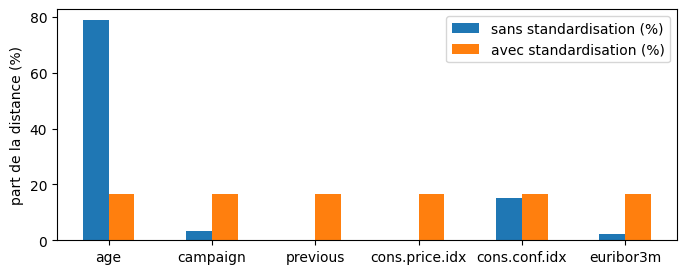

In [5]:
variances_brutes = X[numeriques].var()
variances_standard = pd.DataFrame(StandardScaler().fit_transform(X[numeriques])).var()

part_avant = variances_brutes / variances_brutes.sum() * 100
part_apres = variances_standard.values / variances_standard.sum() * 100

parts = pd.DataFrame({"sans standardisation (%)": part_avant, "avec standardisation (%)": part_apres})
print(parts.round(1))

parts.plot.bar(figsize=(8, 3))
plt.xticks(rotation=0)
plt.ylabel("part de la distance (%)")
plt.show()

Sans standardisation, l'âge fait près de 80 % de la distance. Après standardisation, chaque variable pèse 1/6.

## 3. K-means

On minimise l'inertie : $W = \sum_{j=1}^{k} \sum_{x \in C_j} \lVert x - \mu_j \rVert^2$

On teste k de 2 à 10 (méthode du coude).

k = 2  inertie = 32628  silhouette = 0.22


k = 3  inertie = 29859  silhouette = 0.174


k = 4  inertie = 27995  silhouette = 0.116


k = 5  inertie = 25944  silhouette = 0.121


k = 6  inertie = 24061  silhouette = 0.136


k = 7  inertie = 23009  silhouette = 0.127


k = 8  inertie = 22355  silhouette = 0.12


k = 9  inertie = 21465  silhouette = 0.126


k = 10  inertie = 21027  silhouette = 0.114


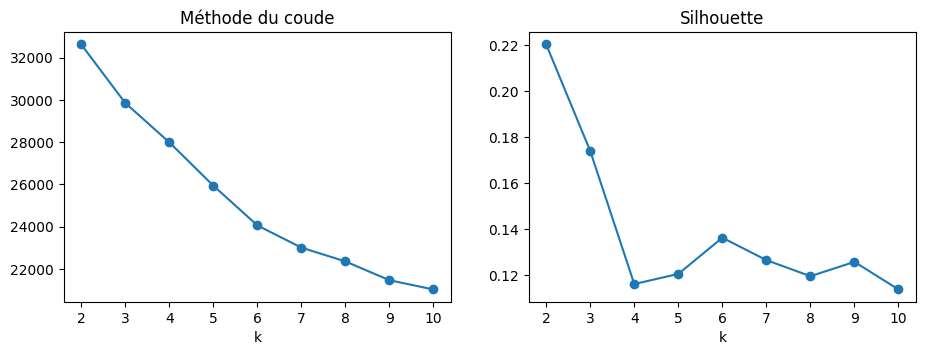

In [6]:
liste_k = range(2, 11)
inerties = []
silhouettes = []

for k in liste_k:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(Xa)
    inerties.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(Xa, kmeans.labels_))
    print("k =", k, " inertie =", round(kmeans.inertia_), " silhouette =", round(silhouettes[-1], 3))

plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(liste_k, inerties, marker="o")
plt.xlabel("k")
plt.title("Méthode du coude")
plt.subplot(1, 2, 2)
plt.plot(liste_k, silhouettes, marker="o")
plt.xlabel("k")
plt.title("Silhouette")
plt.show()

Pas de coude net. La silhouette est la plus haute pour k = 2. Les groupes sont peu séparés.

## 4. K-medoids sur Gower

Comme K-means, mais chaque centre est un vrai client (le médoïde).

Remarque : scikit-learn-extra ne marche pas avec NumPy 2, on utilise la fonction `kmedoids` du fichier fonctions.py.

In [7]:
groupes_kmed, medoides, cout = fonctions.kmedoids_meilleur(G, k=3)
print("Taille des groupes :", np.bincount(groupes_kmed))
X.iloc[medoides]

Taille des groupes : [1279 1717 1004]


,age,job,marital,education,default,housing,loan,contact,campaign,previous,poutcome,cons.price.idx,cons.conf.idx,euribor3m
38,36,blue-collar,married,high.school,no,no,no,telephone,3,0,nonexistent,93.994,-36.4,4.857
994,42,admin.,married,university.degree,no,yes,no,cellular,2,0,nonexistent,93.918,-42.7,4.957
3279,35,admin.,single,university.degree,no,no,no,cellular,1,0,nonexistent,92.893,-46.2,1.334


## 5. K-prototypes

$d(x, \mu) = \sum_{num} (x_v - \mu_v)^2 + \gamma \sum_{cat} \mathbb{1}[x_v \neq \mu_v]$

In [8]:
Xp = Xb.copy()
Xp[numeriques] = StandardScaler().fit_transform(Xp[numeriques])
positions_cat = [Xp.columns.get_loc(c) for c in categorielles]   # colonnes catégorielles

kproto = KPrototypes(n_clusters=3, init="Cao", n_init=3, random_state=42)
groupes_kproto = kproto.fit_predict(Xp.values, categorical=positions_cat)
print("gamma :", kproto.gamma)
print("Taille des groupes :", np.bincount(groupes_kproto))

gamma : 0.5
Taille des groupes : [2316  336 1348]


## 6. GMM

$p(x) = \sum_{j=1}^{k} \pi_j \, \mathcal{N}(x \mid \mu_j, \Sigma_j)$

On choisit k avec $BIC = -2\ln L + m \ln n$ et $AIC = -2\ln L + 2m$ (plus petit = mieux).

GMM est fait sur les 10 premières composantes de la PCA (80 % de la variance).

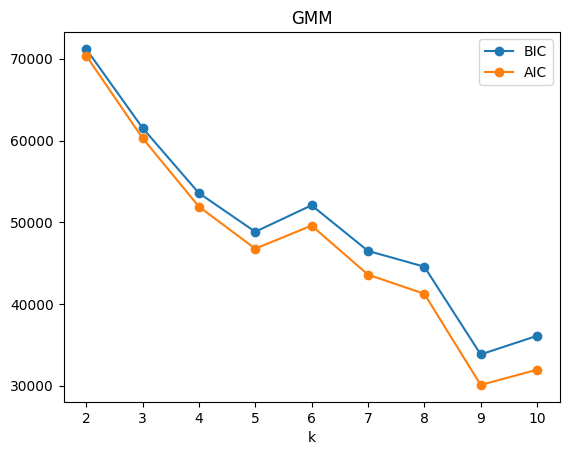

k avec le plus petit BIC : 9


In [9]:
Z10 = PCA(n_components=10, random_state=42).fit_transform(Xa)
bic = []
aic = []

for k in liste_k:
    gmm = GaussianMixture(n_components=k, n_init=3, random_state=42)
    gmm.fit(Z10)
    bic.append(gmm.bic(Z10))
    aic.append(gmm.aic(Z10))

plt.plot(liste_k, bic, marker="o", label="BIC")
plt.plot(liste_k, aic, marker="o", label="AIC")
plt.xlabel("k")
plt.legend()
plt.title("GMM")
plt.show()
print("k avec le plus petit BIC :", liste_k[np.argmin(bic)])

BIC et AIC baissent presque tout le temps : pas de choix net.

## 7. Comparaison pour k = 3

La silhouette est calculée sur la même distance (Gower) pour toutes les méthodes.

In [10]:
groupes_kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xa)
groupes_gmm = GaussianMixture(n_components=3, n_init=3, random_state=42).fit(Z10).predict(Z10)

methodes = {"K-means": groupes_kmeans, "K-medoids": groupes_kmed,
            "K-prototypes": groupes_kproto, "GMM": groupes_gmm}

for nom in methodes:
    groupes = methodes[nom]
    sil = silhouette_score(G, groupes, metric="precomputed")
    print(nom, ": silhouette =", round(sil, 3), " tailles =", np.bincount(groupes))

K-means : silhouette = 0.173  tailles = [2335 1095  570]
K-medoids : silhouette = 0.133  tailles = [1279 1717 1004]
K-prototypes : silhouette = 0.115  tailles = [2316  336 1348]


GMM : silhouette = 0.177  tailles = [1411 1319 1270]


Conclusion : la standardisation est indispensable, et les 4 méthodes donnent des groupes peu séparés (silhouette < 0,2).